# Comprender las visitas antes de modelar

**Pregunta:** ¿qué distingue una visita con compra y cómo cambia el comportamiento? El EDA inicial usa días **1–296**. Los diagnósticos posteriores se limitan al desarrollo **1–620** y se identifican aparte. El test queda reservado.

In [1]:
from pathlib import Path
import os
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd() if (Path.cwd() / "review_config.yml").exists() else Path.cwd().parent
os.chdir(ROOT)
from ferreyros_propension.review import read_config
config = read_config()
OUTPUT = ROOT / config["output"]
assert config["development_end"] == 620


C:\Users\errop\OneDrive\Documentos\Projects\ferreyros-propension\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Qué se predice y qué se conoce

Se estima compra **antes del resultado de una visita conocida**. Perfil y ofertas actuales se consideran disponibles. El historial usa resultados anteriores; se actualiza entre visitas durante validación, mientras el modelo y su umbral permanecen fijos. No es un pronóstico de ventas a varios meses.

In [2]:
from ferreyros_propension.review_eda import write_eda
write_eda(config)
display(Markdown((OUTPUT / "eda/EDA.md").read_text(encoding="utf-8")))

# EDA inicial y diagnóstico temporal de desarrollo

## Contrato y límites

Se estima compra antes del resultado de una visita conocida. Perfil y ofertas actuales se consideran disponibles; los resultados de visitas anteriores se conocen antes de cada nueva visita. Las variables históricas se actualizan durante validación únicamente con resultados anteriores. Las asociaciones no identifican efectos causales.
Días 621–730 excluidos antes de validaciones y construcción de variables. No se consultaron artefactos de test.

## EDA inicial: días 1–296

- 25,754 visitas de 500 clientes; 6,124 visitas con compra (23.8%).
- Un cliente registra una mediana de 50 visitas. La mediana de su conversión individual es 19.0%; no debe confundirse con la conversión agregada de visitas.
- La conversión de los 43 bloques de siete días varía entre 11.2% y 39.8%. El último bloque tiene dos días: comparar sus volúmenes brutos exige considerar su menor duración.
- El mapa recencia/frecuencia cuenta visitas, no clientes únicos. Un cliente puede aparecer en distintas celdas; las celdas con poco soporte no justifican conclusiones firmes.
- Las tablas de promociones y edad incluyen visitas, compras y clientes únicos; las tasas se calculan por visita. Las mismas personas pueden aparecer en ambos grupos de exposición promocional.

## Calidad y semántica en desarrollo

- 50,556 visitas, 500 clientes y 24 columnas originales; 0 celdas faltantes y 0 filas duplicadas.
- Se construyen 106 variables; se comparan 5 grupos de variables. Cambios de campos de perfil dentro del cliente: 0.
- `ultima_marca_comprada` coincide con la marca de la visita anterior; `ultima_cantidad_comprada` coincide con la incidencia de compra de la visita anterior. La comprobación cuantitativa está en `semantica_historial.csv`.

## Diagnóstico temporal: no es EDA inicial

Las siguientes tasas describen los períodos exteriores de desarrollo. Ya examinados históricamente, sirven para investigar estabilidad; no son una confirmación independiente.

- Días 1–296: 25,754 visitas, 500 clientes y conversión 23.8%.
- Días 297–404: 8,409 visitas, 500 clientes y conversión 26.8%.
- Días 405–512: 8,364 visitas, 500 clientes y conversión 25.3%.
- Días 513–620: 8,029 visitas, 500 clientes y conversión 26.1%.

## Lecturas y siguientes hipótesis

Investigar tendencia de tienda estrictamente rezagada, cambios de frecuencia del cliente y diferencias en respuesta histórica a ofertas. Contrastarlas mediante ablaciones dentro de validación temporal; estas visuales no demuestran causalidad ni explican por sí solas los errores del modelo.

Visuales: `01_semanas_iniciales.png`, `02_clientes_iniciales.png`, `03_historial_inicial.png`, `04_asociaciones_iniciales.png` y `05_diagnostico_desarrollo.png`. Tablas CSV conservan denominadores y límites de períodos.


## Calidad y significado de los campos

La marca y cantidad actuales describen el resultado y se excluyen de los predictores. Los campos suministrados como “última compra” se contrastan con la visita previa; no se acepta su nombre como definición suficiente.

In [3]:
display(pd.read_csv(OUTPUT / "data_quality.csv"))
display(pd.read_csv(OUTPUT / "history_semantics.csv"))

,Unnamed: 0,value
0,filas,50556
1,clientes,500
2,columnas,24
3,faltantes,0
4,duplicados,0
5,incoherencia_cantidad,0
6,incoherencia_marca,0


,variable,hipotesis,coincidencia
0,ultima_marca_comprada,visita_anterior,1.000000
1,ultima_marca_comprada,compra_anterior,0.345538
2,ultima_marca_comprada,evento_actual,0.687258
3,ultima_cantidad_comprada,visita_anterior,0.815175
4,ultima_cantidad_comprada,compra_anterior,0.160713
5,ultima_cantidad_comprada,evento_actual,0.635375
6,ultima_cantidad_comprada,incidencia_visita_anterior,1.000000


## Compra por semana: tasa y volumen

**Nivel: visita.** Las semanas son bloques relativos de siete días; el último bloque es parcial.

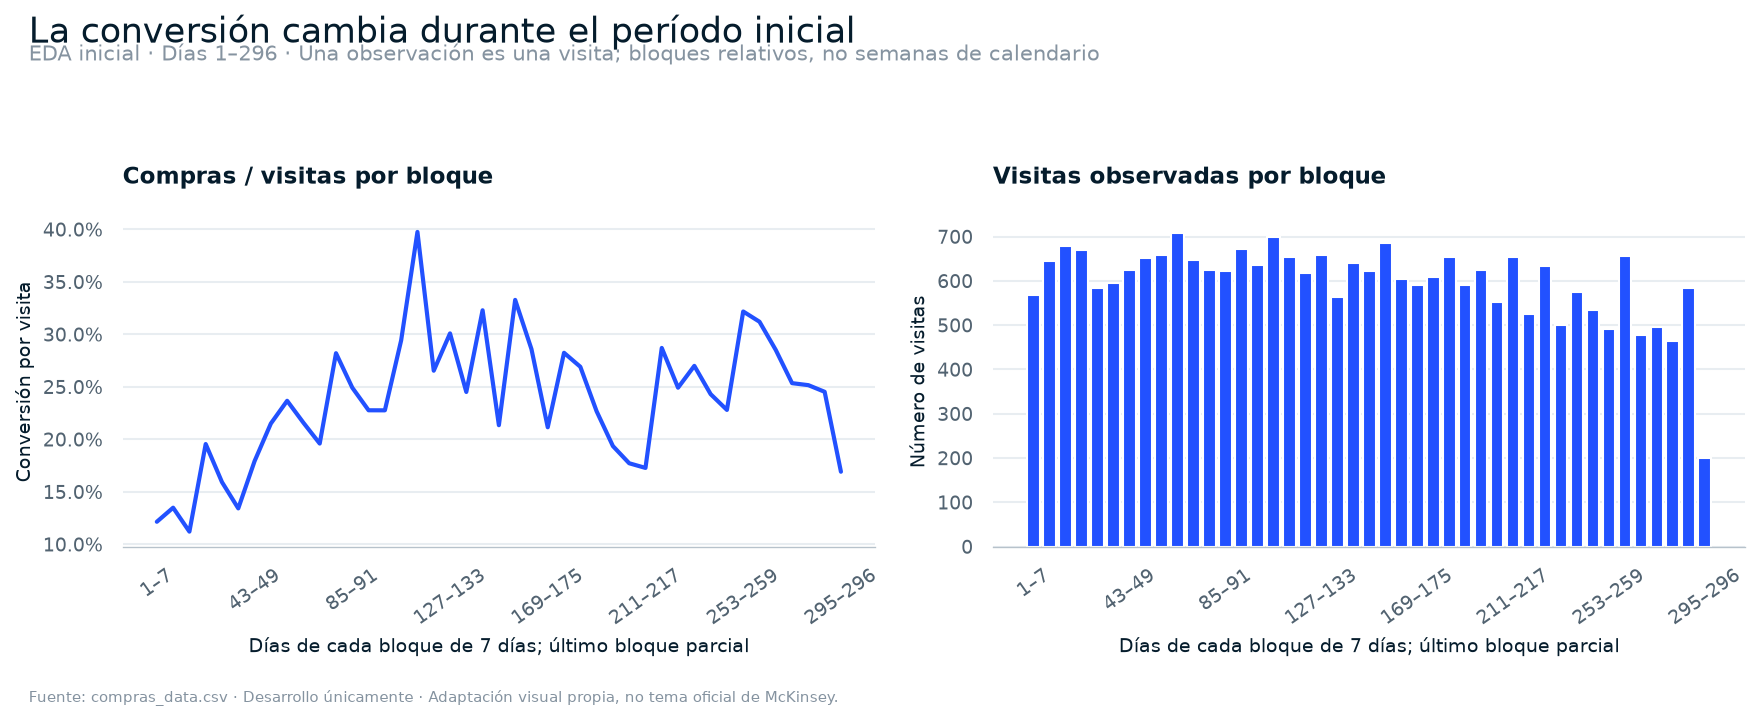

In [4]:
display(Image(filename=str(OUTPUT / "eda/01_semanas_iniciales.png")))

## Los clientes tienen frecuencias y conversiones diferentes

**Nivel: cliente.** Cada observación del gráfico corresponde al resumen de una persona, no a una visita.

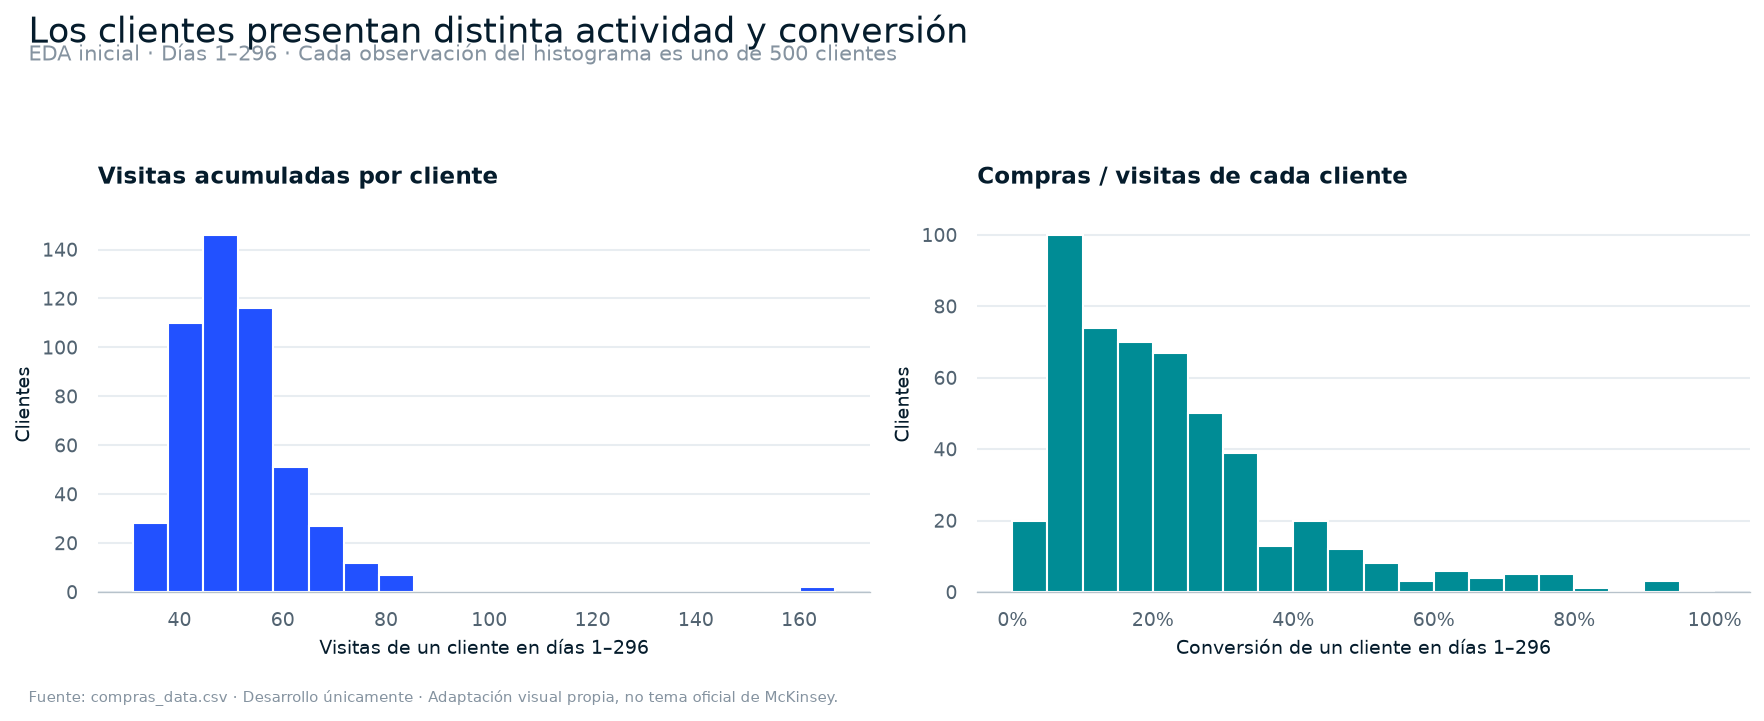

In [5]:
display(Image(filename=str(OUTPUT / "eda/02_clientes_iniciales.png")))

## Historial antes de cada visita

**Nivel: visita.** Un cliente puede aparecer en varias celdas a lo largo del tiempo. La tasa necesita interpretarse junto con el número de visitas de soporte.

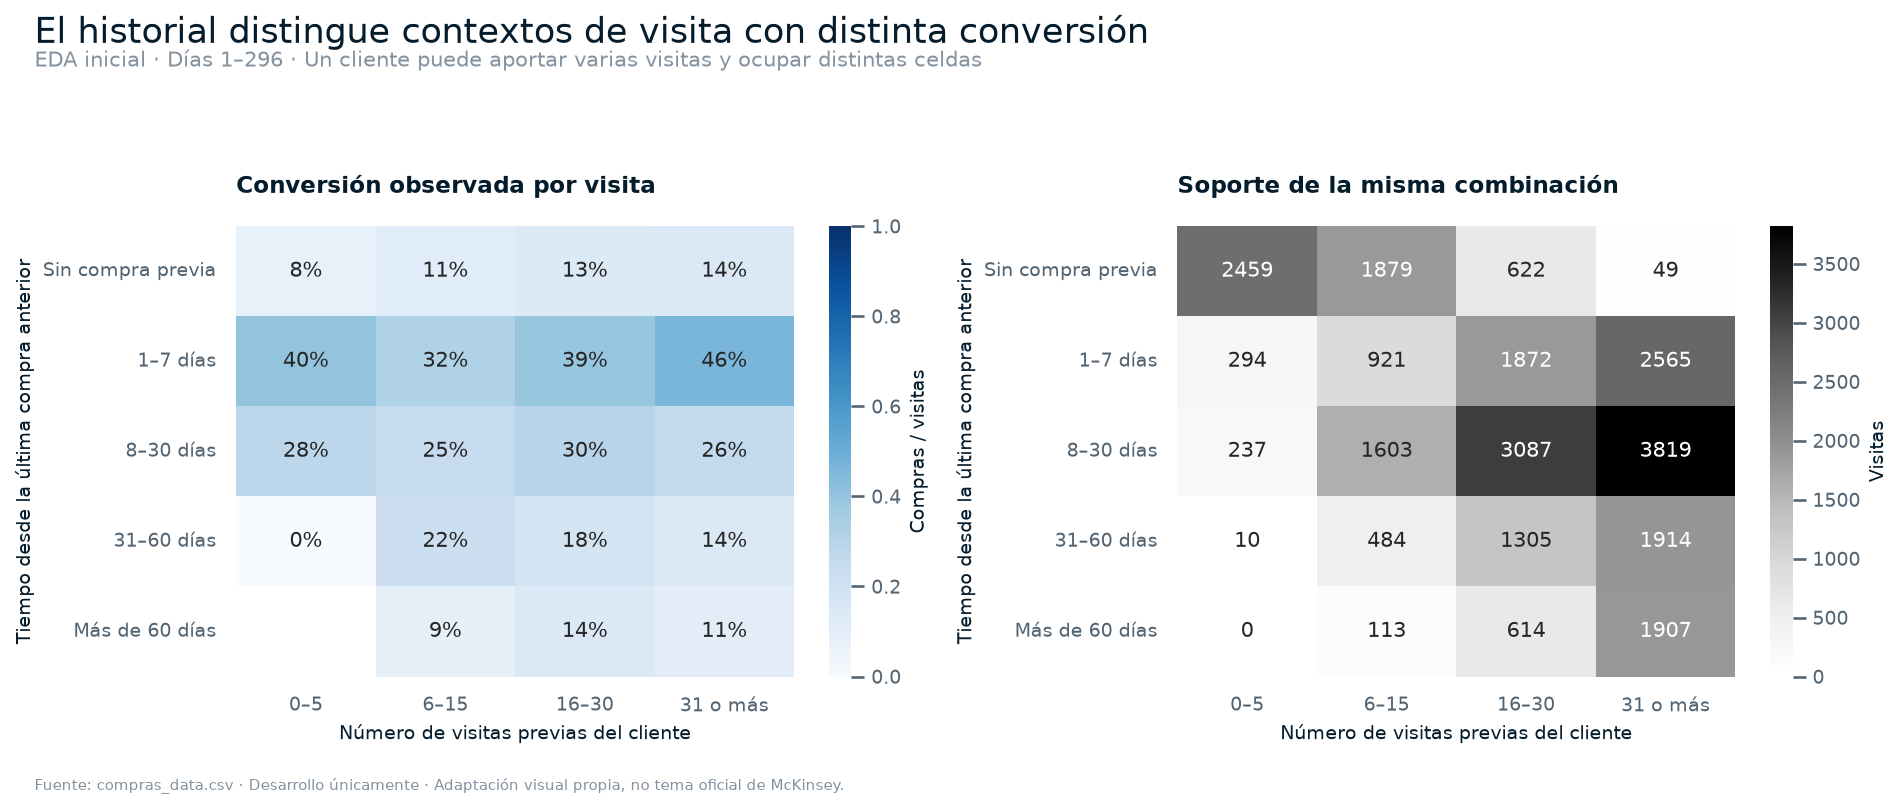

In [6]:
display(Image(filename=str(OUTPUT / "eda/03_historial_inicial.png")))

## Ofertas y perfil: asociaciones, no efectos causales

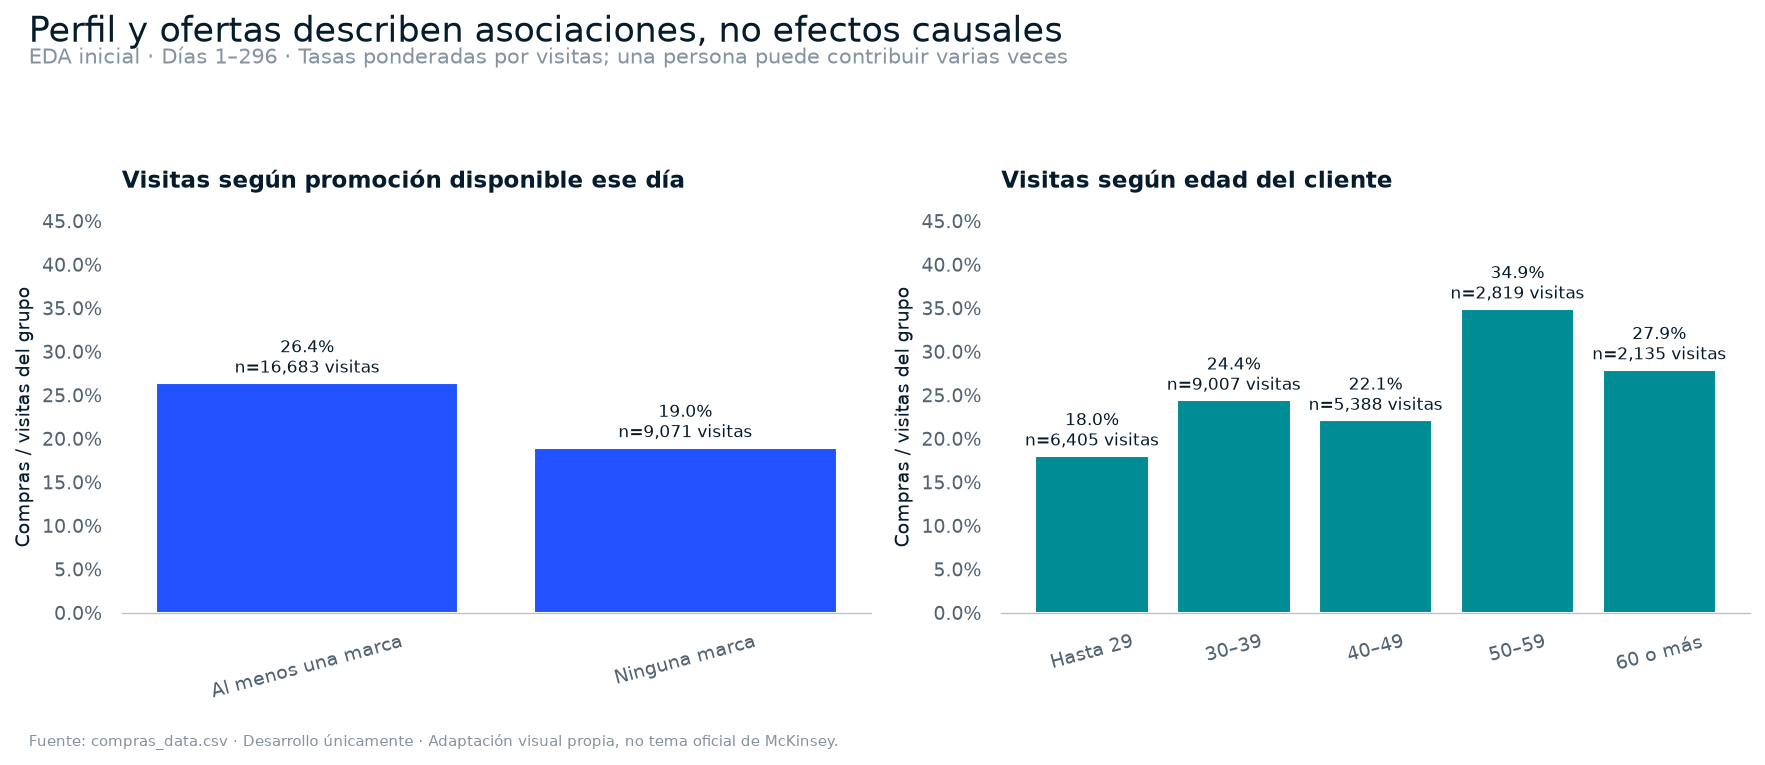

In [7]:
display(Image(filename=str(OUTPUT / "eda/04_asociaciones_iniciales.png")))

## Diagnóstico temporal de desarrollo

Estos períodos ya fueron examinados en el proyecto. La figura sirve para investigar estabilidad; no es un test independiente.

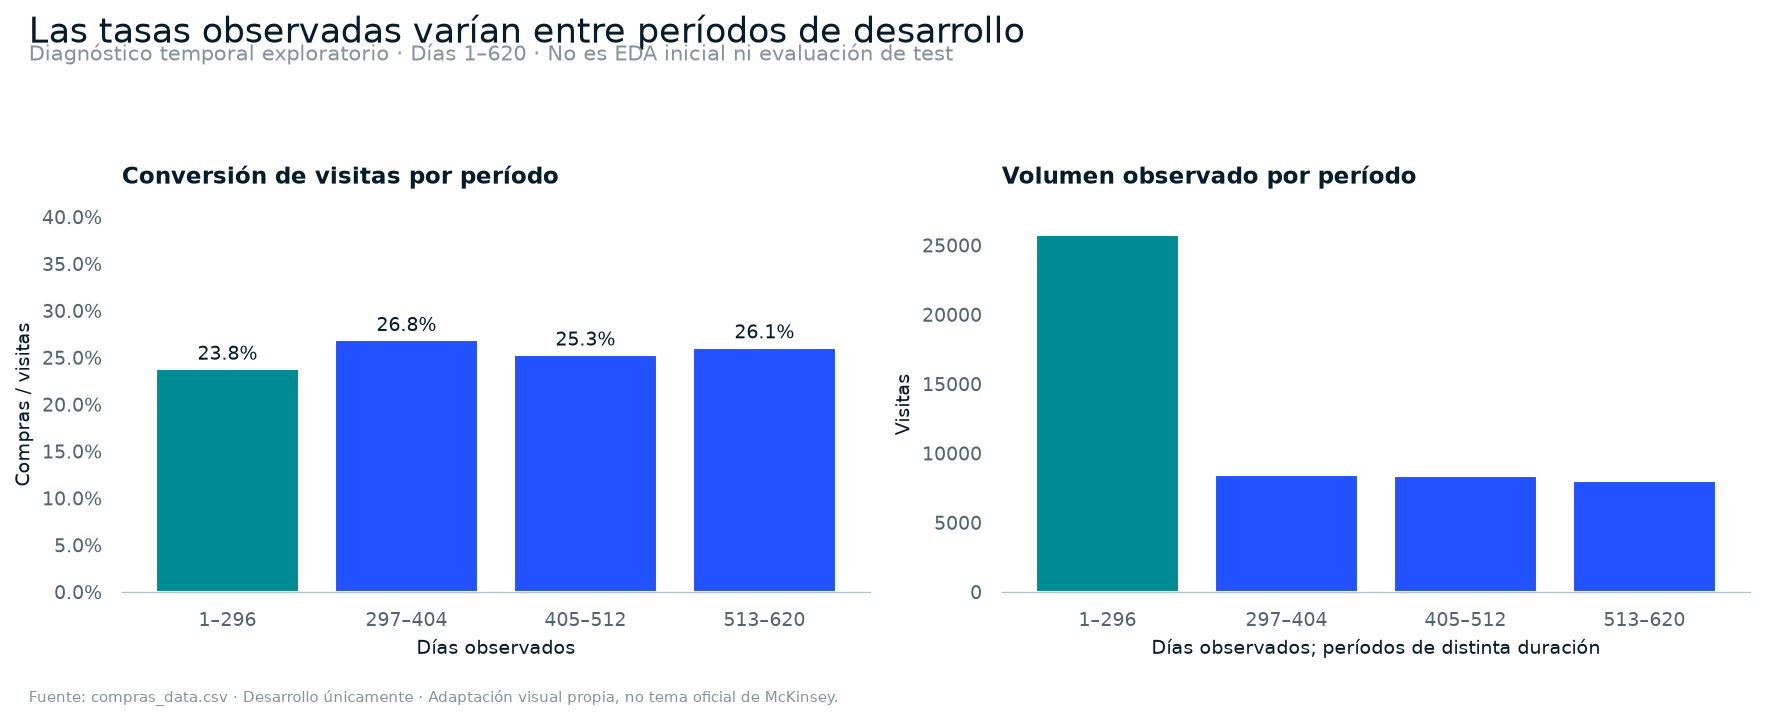

In [8]:
display(Image(filename=str(OUTPUT / "eda/05_diagnostico_desarrollo.png")))